# D3 EDA: Does Sephora India show up in AI shopping answers?
This notebook only **shows** the analysis. The calculations live in `src/beyondsearch/` (unit-tested), and the study-specific wording lives in `configs/beauty_india.yaml`. That is what makes it traceable, reliable, reproducible and observable.

| CRISP-DM phase | Where it happens |
|---|---|
| Business understanding | Section 0 (decision and question) and the project charter |
| Data understanding | Sections 2, 4, 5 (`validate.py`, `analysis.py`) |
| Data preparation | Section 3 (`ingest.py`, `features.py`) |
| Modelling | Next step (D4): outcome and inputs are fixed in Section 8 |
| Evaluation | Sections 6 and 6b (hypothesis tests, robustness) |
| Deployment / monitoring | `python -m beyondsearch run` (repeatable, logged, with a run manifest) |

In [1]:
# Setup: find the repository root, load the configuration, start a traceable session.
import sys, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs").exists())
sys.path.insert(0, str(ROOT / "src"))                      # works without installing the package
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown
from beyondsearch.config import Config
from beyondsearch.iotools import read_csv_checked, sha256_file
from beyondsearch.manifest import environment
from beyondsearch.validate import validate_inputs
from beyondsearch.analysis import run_analysis
from beyondsearch.figures import FIGURES
from beyondsearch.report import five_insights, hypothesis_results
warnings.filterwarnings("ignore")
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)
cfg = Config.load(ROOT / "configs" / "beauty_india.yaml")
nar = cfg["narrative"]
print("project:", cfg["project"], "| data version:", cfg["data_version"], "| seed:", cfg["seed"])

project: Beyond the Search Bar: beauty and skincare, India (pilot: Sephora India) | data version: data-v0.9 | seed: 42


## 0. Decision, question and honest limit

In [2]:
display(Markdown(f"**Team:** {nar['team']}  \n**Business decision this supports:** {nar['decision']}  \n\n**Analytics question:** {nar['question']}  \n\n**Status:** {nar['status']}  \n\n**Honest limit:** {nar['honest_limit']}"))

**Team:** Team L: Saba Gul, Saurav Kumar, Agnik Majumder  
**Business decision this supports:** Sephora India's marketing and digital team must decide which content and product-feed fixes to make first so that AI shopping assistants name and link Sephora India when shoppers ask for beauty products.  

**Analytics question:** In our panel of AI answers, how often are Sephora India and Nykaa named and linked, and does this change by engine, question type, product category or repeat run?  

**Status:** Part submission. All genuine collected answers are used (single chats, batched chats and API runs). The collection method is tracked as a variable and tested for bias, not used to throw rows away. This is a live project on a real company, so the sample keeps growing.  

**Honest limit:** This is an exploration of a manual sample. It does not prove what real shoppers see, and it has no sales data.

## 1. Hypotheses (written before looking at any chart)
Each one is tied to the business decision. The expected direction is written first, so the charts cannot change our minds afterwards. They are stored in the configuration file, so the notebook, the report and the tests all use the same wording.

In [3]:
rows = ["| # | Hypothesis | Business question | Test | Expected |", "|---|---|---|---|---|"]
rows += [f"| {h['id']} | {h['statement']} | {h['question']} | {h['test']} | {h['expected']} |" for h in cfg["hypotheses"]]
display(Markdown("\n".join(rows)))

| # | Hypothesis | Business question | Test | Expected |
|---|---|---|---|---|
| H1 | In unbranded prompts, Nykaa is named in a larger share of answers than Sephora India | Are we behind the main competitor in AI answers? | Paired McNemar test, same answer | Nykaa higher |
| H2 | Sephora India is named more often when the shopper asks where to buy (a retailer question) than when they ask for a product (need, budget or shortlist question) | Is our visibility a retailer problem or a product problem? | Fisher exact test (small retailer-question count); chi-square also reported | retailer questions higher |
| H3 | Sephora India mention rate differs by AI engine | Which engine should we fix first? | Chi-square across engines | differences exist |
| H4 | Sephora India mention rate differs by category, and is higher for fragrance and premium items than for haircare | Where is our strongest and weakest category? | Chi-square across categories | differences exist |
| H5 | When an answer links to a retailer, it links to Nykaa more often than to Sephora India | Do AI engines send traffic to us or to competitors? | Paired McNemar test on links | Nykaa higher |
| H6 | The same prompt on the same engine gives different cited sources across repeat runs (overlap below 1) | Can we trust one answer as the truth, and how many runs do we need? | Jaccard overlap of cited domains | overlap well below 1 |

## 2. Load and validate the data
Nothing is analysed until the data passes the checks. Warnings are shown, not hidden.

In [4]:
rl, panel, sched = (read_csv_checked(cfg.path(k), label=k) for k in ("response_log", "prompt_panel", "run_schedule"))
check = validate_inputs(cfg, rl, panel, sched)
display(pd.DataFrame([f.__dict__ for f in check.findings])[["level", "check", "message", "count"]])
check.raise_if_errors()
print("rows logged:", len(rl), "| planned runs:", len(sched), f"| progress: {len(rl)/len(sched):.0%}")

,level,check,message,count
0,WARN,collector_differs,"collector differs from the schedule (allowed, ...",40
1,WARN,setting_not_recorded,'memory_personalisation_off' is blank for 160 ...,160
2,WARN,setting_not_recorded,'logged_in' is blank for 160 rows (blank means...,160
3,INFO,html_entities,answer text contains HTML codes such as &#x20;...,30
4,INFO,progress,238 answers logged of 600 planned (40%),238


rows logged: 238 | planned runs: 600 | progress: 40%


## 3. Build simple features from the raw answers
No AI model is used here. Plain text rules, so anyone can check them (`src/beyondsearch/features.py`):
- `*_mention`: the retailer name appears in the answer text.
- `*_cited`: a link in the answer belongs to that retailer's website.
- `first_pos_*`: how early the retailer appears (0 = start, 1 = end).

These rules count only the retailer name, so product-only answers count as "no retailer named". All genuine answers are used; the collection method is tested as a possible bias in Section 4, not used to throw rows away.

In [5]:
res = run_analysis(cfg, rl, panel, sched)
display(pd.DataFrame({e: {"regular expression": v["pattern"], "link contains": v["domain"]} for e, v in cfg["entities"].items()}).T)
print("answers used:", res.counts["rows_usable"], "| excluded:", res.counts["rows_excluded"],
      "| primary (unbranded):", res.counts["primary_n"], "| branded comparison:", res.counts["branded_n"])
display(res.tables["method_counts"]); display(res.tables["engine_by_method"])
res.frames["valid"][["run_id", "engine", "category", "words", "n_domains", "sephora_mention", "nykaa_mention"]].head()

,regular expression,link contains
sephora,sephora,sephora.
nykaa,nykaa,nykaa.
tira,\btira\b,tirabeauty.
purplle,purplle,purplle.
amazon,amazon,amazon.
myntra,myntra,myntra.


answers used: 238 | excluded: 0 | primary (unbranded): 222 | branded comparison: 16


,collection_method,rows
0,batched_chat,141
1,single_chat,57
2,api,40


collection_method,api,batched_chat,single_chat,All
engine,,,,
chatgpt,0,14,44,58
claude,0,56,0,56
gemini,40,29,0,69
google_ai_mode,0,34,0,34
perplexity,0,8,13,21
All,40,141,57,238


,run_id,engine,category,words,n_domains,sephora_mention,nykaa_mention
0,S001,chatgpt,sunscreen,426,11,False,True
1,S002,google_ai_mode,sunscreen,130,0,False,False
2,S003,chatgpt,retailer,198,0,True,True
3,S004,gemini,fragrance,155,0,False,False
4,S005,chatgpt,fragrance,246,2,True,False


## 4. Representativeness and bias checks
Three things could bias the sample: the engine mix, who collected, and how the answer was collected. We test each one instead of dropping data.

engine by intent


intent,budget,compare,need,shortlist,where_to_buy,All
engine,,,,,,
chatgpt,14,4,17,17,6,58
claude,18,2,16,16,4,56
gemini,22,5,23,19,0,69
google_ai_mode,9,3,9,12,1,34
perplexity,8,2,4,6,1,21
All,71,16,69,70,12,238


category by engine


engine,chatgpt,claude,gemini,google_ai_mode,perplexity,All
category,,,,,,
acne_skincare,5,10,8,4,2,29
foundation,10,7,10,5,3,35
fragrance,9,10,11,6,4,40
haircare,5,7,14,5,2,33
lipstick,9,8,11,5,2,35
retailer,10,6,5,4,3,28
sunscreen,10,8,10,5,5,38
All,58,56,69,34,21,238


runs per collector


,runs
collector,
Saba,160
Agnik,78


planned vs collected


,planned_share,collected_share
engine,,
chatgpt,0.333,0.244
claude,0.133,0.235
gemini,0.200,0.290
google_ai_mode,0.267,0.143
perplexity,0.067,0.088


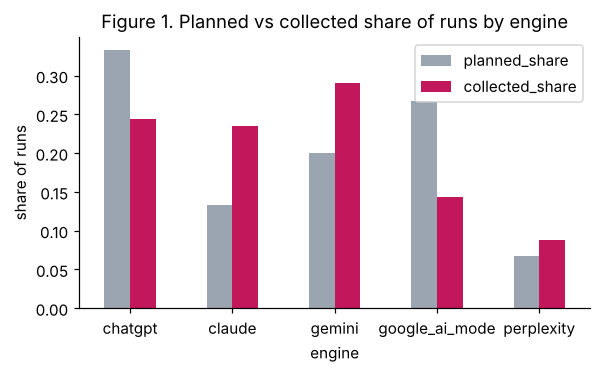

collector vs Sephora mention: chi2=2.55, p=0.110
collection_method vs Sephora mention: chi2=0.79, p=0.672

ChatGPT only, Nykaa named by collection method:


nykaa_mention,False,True
collection_method,,
batched_chat,5,8
single_chat,16,25


Fisher exact p = 1.0


In [6]:
for name in ("engine_by_intent", "category_by_engine", "runs_per_collector", "planned_vs_collected"):
    print(name.replace("_", " ")); display(res.tables[name])
fig = FIGURES[0](res, cfg); plt.show()
b = res.tests["bias"]
for var, r in b.items():
    if isinstance(r, dict): print(f"{var} vs Sephora mention: chi2={r['chi2']:.2f}, p={r['p']:.3f}")
print("\nChatGPT only, Nykaa named by collection method:"); display(res.tables["bias_engine_method"])
print("Fisher exact p =", None if b['engine_method_fisher_p'] is None else round(b['engine_method_fisher_p'], 3))

## 5. Distributions: what do the answers look like?

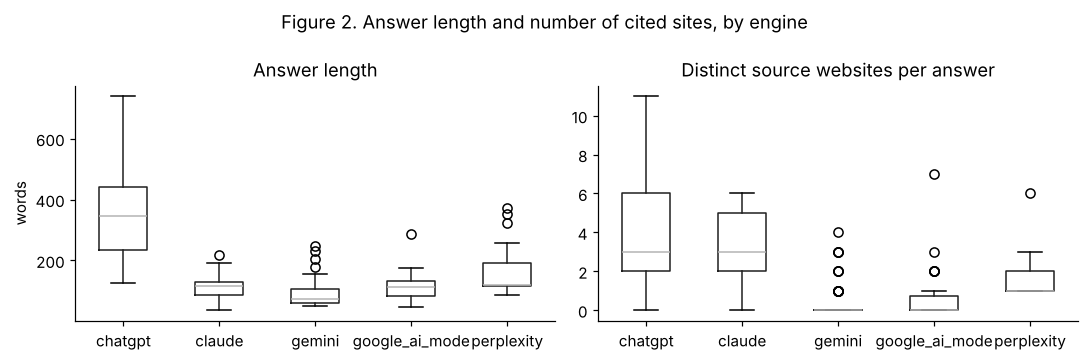

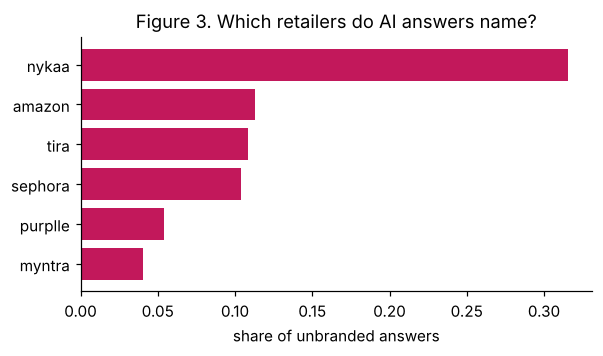

In [7]:
FIGURES[1](res, cfg); plt.show()
FIGURES[2](res, cfg); plt.show()

## 6. Hypothesis tests

Nykaa named,False,True
Sephora named,,
False,146,53
True,6,17


Sephora named in 10.4%, Nykaa in 31.5% of unbranded answers; McNemar p = 1.754e-10


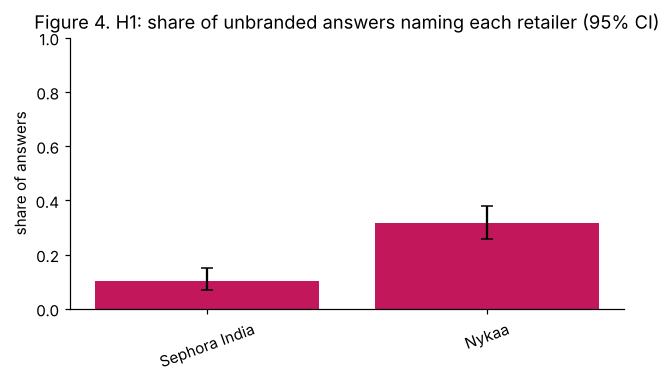

In [8]:
# H1: Nykaa vs Sephora named, same answers (paired test)
t = res.tests["H1"]
display(res.tables["H1_table"].rename_axis(index="Sephora named", columns="Nykaa named"))
print(f"Sephora named in {t['focal_rate']:.1%}, Nykaa in {t['comp_rate']:.1%} of unbranded answers; McNemar p = {t['p']:.4g}")
FIGURES[3](res, cfg); plt.show()

,question_type,sum,count,rate,lo,hi
0,product question,13,210,0.061905,0.036531,0.103019
1,retailer question,10,12,0.833333,0.551969,0.953035


chi-square (chi2, p, dof): (64.66904553825024, 8.859579503198909e-16, 1)
Fisher exact (use this one: only 12 retailer-question answers): odds ratio 75.8, p = 0.00000


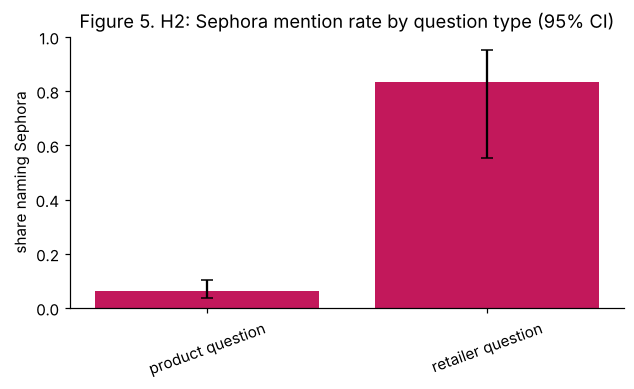

In [9]:
# H2: retailer question ("where to buy") vs product question (need, budget, shortlist)
display(res.tables["H2_rates"]); t = res.tests["H2"]
print("chi-square (chi2, p, dof):", t["chi"])
print(f"Fisher exact (use this one: only {t['n_retailer_q']} retailer-question answers): odds ratio {t['fisher_odds']:.1f}, p = {t['fisher_p']:.5f}")
FIGURES[4](res, cfg); plt.show()

,engine,sum,count,rate,lo,hi
0,chatgpt,12,54,0.222222,0.131954,0.349387
1,claude,5,54,0.092593,0.040201,0.199099
2,gemini,3,64,0.046875,0.016069,0.128997
3,google_ai_mode,1,31,0.032258,0.005717,0.161941
4,perplexity,2,19,0.105263,0.029359,0.313941


chi-square (chi2, p, dof): (12.16924067416386, 0.016136135964009476, 4)


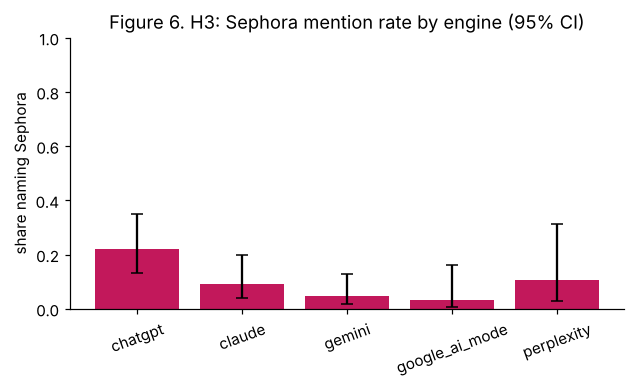

In [10]:
# H3: engine
display(res.tables["H3_rates"]); print("chi-square (chi2, p, dof):", res.tests["H3"]["chi"])
FIGURES[5](res, cfg); plt.show()

,category,sum,count,rate,lo,hi
0,acne_skincare,0,29,0.000000,0.000000,0.116970
1,foundation,6,35,0.171429,0.081026,0.326823
2,fragrance,3,40,0.075000,0.025836,0.198642
3,haircare,1,33,0.030303,0.005369,0.153187
4,lipstick,2,35,0.057143,0.015813,0.186071
5,retailer,10,12,0.833333,0.551969,0.953035
6,sunscreen,1,38,0.026316,0.004661,0.134949


chi-square, all categories: (79.41137717772493, 4.7269475869528e-15, 6)
chi-square, product categories only: (10.67137444441746, 0.05829934007548647, 5) (small expected counts: indicative)


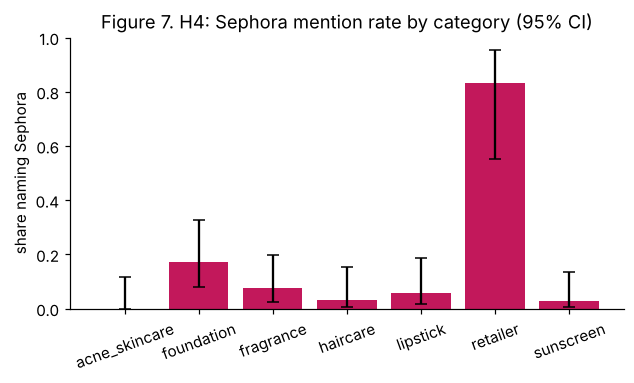

In [11]:
# H4: category (and again without the retailer category, because it drives the first result)
display(res.tables["H4_rates"]); t = res.tests["H4"]
print("chi-square, all categories:", t["chi"]); print("chi-square, product categories only:", t["chi_product_only"], "(small expected counts: indicative)")
FIGURES[6](res, cfg); plt.show()

In [12]:
# H5: links, among answers that link to at least one retailer site
t = res.tests["H5"]; print("answers with a retailer link:", t["n_linked"], "of", t["n_primary"])
if t["n_linked"]:
    display(res.tables["H5_table"].rename_axis(index="Sephora linked", columns="Nykaa linked"))
    print(f"Sephora linked in {t['focal_rate']:.1%}, Nykaa in {t['comp_rate']:.1%}; McNemar p = {t['p']:.4g}")

answers with a retailer link: 74 of 222


Nykaa linked,False,True
Sephora linked,,
False,12,45
True,7,10


Sephora linked in 23.0%, Nykaa in 74.3%; McNemar p = 6.974e-08


prompt-engine pairs with 2+ runs: 68 | mean overlap: 0.3


,mean,median,count
engine,,,
chatgpt,0.26,0.23,16
claude,0.36,0.27,19
gemini,0.05,0.00,10
google_ai_mode,0.20,0.00,5
perplexity,0.80,1.00,5


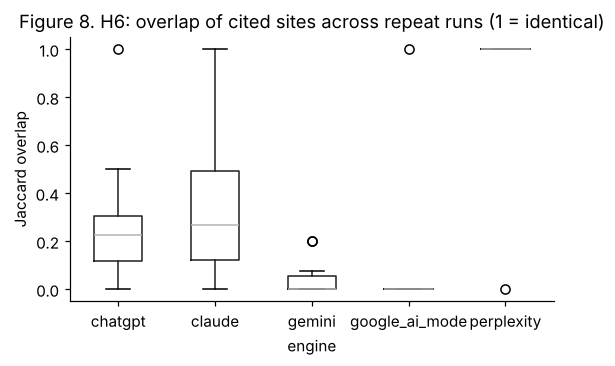

In [13]:
# H6: repeatability, Jaccard overlap of cited sites between runs of the same prompt and engine
t = res.tests["H6"]; print("prompt-engine pairs with 2+ runs:", t["n_pairs"], "| mean overlap:", None if t["mean"] is None else round(t["mean"], 2))
if t["n_pairs"]:
    display(res.tables["H6_by_engine"]); FIGURES[7](res, cfg); plt.show()
else:
    print("Not enough repeat runs yet: collect at least 2 runs of the same prompt on the same engine.")

## 6b. Robustness: does the collection method change the conclusion?
Answers from one fresh chat per question are the cleanest. We repeat the headline comparison on that subset and by method. Nothing is removed from the main analysis.

,engine,collection_method,n,focal,comp,focal_link,comp_link
0,chatgpt,batched_chat,13,0.38,0.62,0.31,0.31
1,chatgpt,single_chat,41,0.17,0.61,0.17,0.46
2,claude,batched_chat,54,0.09,0.30,0.02,0.20
3,gemini,api,36,0.03,0.14,0.00,0.00
4,gemini,batched_chat,28,0.07,0.11,0.07,0.11
5,google_ai_mode,batched_chat,31,0.03,0.10,0.03,0.10
6,perplexity,batched_chat,7,0.29,0.86,0.29,0.86
7,perplexity,single_chat,12,0.00,0.33,0.00,0.75


Single fresh chats only (n=53): Sephora 13%, Nykaa 55%, McNemar p = 2.98e-06


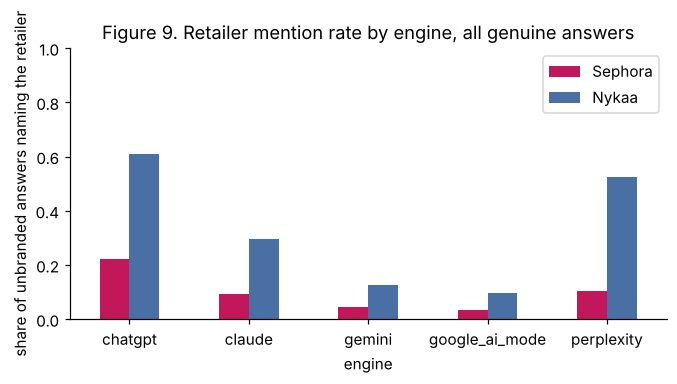

In [14]:
display(res.tables["robust_by_engine_method"]); t = res.tests["robust"]
if t["n_single"]:
    print(f"Single fresh chats only (n={t['n_single']}): Sephora {t['focal_rate']:.0%}, Nykaa {t['comp_rate']:.0%}, McNemar p = {t['p']:.4g}")
FIGURES[8](res, cfg); plt.show()

## 7. Insight log
Evidence numbers come from the code. The so-what and confidence wording is the analyst's, kept in the configuration file.

In [15]:
pd.set_option("display.max_colwidth", 200)
display(res.insight_log)

,hypothesis,insight (evidence),figure,so what for the decision,confidence
0,H1,"Sephora named in 10% vs Nykaa 32% of 222 unbranded answers; 53 name only Nykaa, 6 only Sephora (McNemar p<0.001)",Figure 4,"Nykaa is named about 3.0 times as often as Sephora India. The first goal is to be named at all in product answers, not to win the retailer comparison.","High: large gap, Nykaa ahead on 5 of 5 engines, also in single fresh chats alone (Fig 9)"
1,H2,"Sephora mention rate by question type: product question 6% (n=210), retailer question 83% (n=12) (Fisher p<0.001)",Figure 5,"Sephora shows up when shoppers ask WHERE to buy and rarely when they ask WHAT to buy. Fixes should target product-answer visibility (product pages, feeds, reviews), not brand pages.",Medium: only 12 retailer-question answers
2,H3,"Sephora mention rate by engine: chatgpt 22% (n=54), claude 9% (n=54), gemini 5% (n=64), google_ai_mode 3% (n=31), perplexity 11% (n=19) (chi-square p=0.016)",Figure 6,Engines differ. chatgpt names Sephora most; google_ai_mode least. Weight the fixes by engine usage (see the benchmarking note) and re-check on the updated data.,Medium: engine cells are small (19 to 64) and collection method differs by engine
3,H4,"Sephora mention rate by category: acne_skincare 0%, foundation 17%, fragrance 8%, haircare 3%, lipstick 6%, retailer 83%, sunscreen 3%. Product categories only: chi-square p=0.058.",Figure 7,"Apart from the retailer category, Sephora is weak across product categories, including its core ones. Treat it as a general product-answer problem until more data shows a category pattern.","Low: 20 to 40 answers per category, wide intervals"
4,H5,"Among 74 answers that link to a retailer: Sephora linked in 23%, Nykaa in 74% (McNemar p<0.001)",Table in H5,"When engines send shoppers to a retailer, it is usually Nykaa. This is the traffic side of the visibility gap.",Medium: depends on which engines show links at all
5,H6,"Mean overlap of cited sites across repeat runs: 0.30 (chatgpt 0.26, claude 0.36, gemini 0.05, google_ai_mode 0.20, perplexity 0.80) over 68 prompt-engine pairs",Figure 8,"One answer is not the truth. Cited sites change between runs, so any monitor needs several runs per prompt.",Medium: few repeat pairs per engine
6,Bias,"Engine mix collected: gemini 29%, chatgpt 24%, claude 24%, google_ai_mode 14%, perplexity 9%. Collection method: batched_chat 141, single_chat 57, api 40.",Figure 1,Mix is closer to the plan than before but Saurav's rows and part of Agnik's Google AI Mode rows are still to come. Results are re-run when the data is updated.,High (a fact about our sample)
7,Robust,Single fresh chats only (n=53): Sephora 13% vs Nykaa 55% (McNemar p<0.001); all genuine rows: Sephora 10% vs Nykaa 32%,Figure 9,"The direction does not depend on the collection method. Collection method has no significant effect on Sephora mentions (p=0.67; inside ChatGPT alone p=1.0), so batched and API answers stay in. Me...",Medium-high


## 8. Summary and effect on modelling

In [16]:
verdicts = hypothesis_results(cfg, res)
lines = ["**What we found, hypothesis by hypothesis**", ""] + [f"- **{h['id']}**: {verdicts[h['id']]}" for h in cfg["hypotheses"]]
lines += ["", "**The five insights that matter most**", ""] + [f"{i}. **{h}** {d}" for i, (h, d) in enumerate(five_insights(cfg, res), 1)]
lines += ["", "**How this shapes D4 (modelling)**", ""] + [f"- {x}" for x in nar["d4_notes"]]
display(Markdown("\n".join(lines)))

**What we found, hypothesis by hypothesis**

- **H1**: Supported: 32% vs 10%, p<0.001
- **H2**: Supported: 83% vs 6% (n=12 vs 210)
- **H3**: Supported: 3% to 22% across 5 engines, p=0.016
- **H4**: Borderline among product categories (p=0.058); foundation 17% highest, acne_skincare 0% lowest
- **H5**: Supported: 74% vs 23%, p<0.001
- **H6**: Supported: mean overlap 0.30 over 68 prompt-engine pairs

**The five insights that matter most**

1. **Nykaa is named about 3.0 times as often as Sephora India.** 32% vs 10% of 222 unbranded answers (53 name only Nykaa, 6 only Sephora; McNemar p<0.001). Nykaa is ahead on 5 of 5 engines and in single fresh chats alone (55% vs 13%).
2. **Sephora appears when shoppers ask where to buy, not what to buy.** 83% of 12 retailer questions vs 6% of 210 product questions (Fisher p<0.001). Fix product-answer visibility first.
3. **Engines differ.** Sephora is named in 22% of ChatGPT, 11% of Perplexity, 9% of Claude, 5% of Gemini, 3% of Google AI Mode answers (chi-square p=0.016). Google AI Mode names Sephora least.
4. **Engines link to Nykaa far more than to Sephora.** Of 74 answers with a retailer link, Nykaa is linked in 74% and Sephora in 23%.
5. **One answer is not reliable.** Cited sites overlap 0.30 (1 = identical) between repeat runs of the same question (Gemini 0.05), so any monitor needs several runs per question.

**How this shapes D4 (modelling)**

- Outcome to model: Sephora named (yes/no) per answer. About 10% are positive, so use stratified folds and report precision-recall, not accuracy.
- Inputs: question type, category, engine, collection method, early position in the answer.
- All runs of one prompt stay in the same train or test fold, because repeat runs of a prompt are not independent.
- Only a few retailer-question answers exist, so model product questions first and add where-to-buy when more data arrives.

## 9. Limits of this exploration

In [17]:
display(Markdown("\n".join(f"- {x}" for x in nar["limits"])))

- Part submission: the analysis is re-run when the data is updated. Collected with our own accounts; AI answers change with model versions.
- Engine mix differs from the popularity weights in the plan; the engine and category cells are small, so p-values there are indicative.
- The question-type test rests on a small number of retailer-question answers.
- Rules count the retailer name, not the quality of the recommendation. A brand sold at Sephora is not counted as Sephora.
- Product-only answers rarely name a retailer, so mention rates are low for every retailer. Compare retailers, not absolute levels.
- Gemini API answers and batched chats were collected differently from single chats; the method check shows no significant effect.
- No sales or traffic data: we cannot say what a mention is worth in rupees.

## 10. Traceability: what exactly produced these numbers

In [18]:
trace = {"data version": cfg["data_version"], "configuration sha256": cfg.sha256[:16], "seed": cfg["seed"]}
for k in ("response_log", "prompt_panel", "run_schedule"):
    trace[f"{k} sha256"] = sha256_file(cfg.path(k))[:16]
display(pd.Series(trace, name="value").to_frame())
env = environment(); display(pd.Series({"python": env["python"], **env["packages"]}, name="version").to_frame())
print("To reproduce on any computer:  pip install -r requirements.txt  &&  python -m beyondsearch run")

,value
data version,data-v0.9
configuration sha256,15c25d225826231a
seed,42
response_log sha256,8833d7e5b2122450
prompt_panel sha256,2b5739f0b72cf996
run_schedule sha256,72207aeec8f04633


,version
python,3.13.16
pandas,3.0.5
numpy,2.5.3
scipy,1.18.1
statsmodels,0.15.0
matplotlib,3.11.2
PyYAML,6.0.3
openpyxl,3.1.5


To reproduce on any computer:  pip install -r requirements.txt  &&  python -m beyondsearch run
